# Generate observations configuration

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Edit the `observations` dict below (one entry per instrument).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in `Samoa.json` with the saved file path.

In [1]:
from utils.config import PATHS, resolve
from utils import onshore_sites as obs
from utils import viz as plot

## Parameters

In [2]:
# Define the observations JSON output file name/path manually.
# Example: "inputs/Observations/Samoa_observations.json"
output_observations_file = "inputs/Observations/Samoa_observations.json"
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
AoI      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/AoI_Polygons/Samoa_AoI.shp
topobathy: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GEBCO/Samoa_GEBCO_SMOOTH_NOAA_3s.tiff


## Observations dict

Edit the dictionary below. Keys are unique `instrument_id` strings.

Required per entry:
- `lon`, `lat` — WGS84 coordinates
- `type` — role used downstream (`validation`, `waves`, `spectrum`, `calibration`, `levels`, `ignore`, …)
- `institution` — data provider (e.g. `IMOS`, `NDBC`, `SPREP`)
- `recording` — approximate coverage period as a string (e.g. `"2010-2024"`)

Optional:
- `depth` — water depth in metres (`null` if unknown)
- `name` — human-readable station name
- `role` — overrides `type` when filtering by role in later notebooks
- any extra property (e.g. `msl` for tide gauges) is kept in the GeoJSON

In [3]:
observations: dict[str, dict] = {
    # --- example entries: replace with your real stations ---
    "Apolima_Buoy": {
        "lon": -172.2,
        "lat": -13.88,
        "type": "waves",
        "institution": "SPC",
        "recording": "1989-1990",
        "depth": -80.0,
        "name": "Savaii - Upolu middle buoy",
    },
    "American_Samoa_Buoy": {
        "lon": -170.493,
        "lat": -14.265,
        "type": "waves",
        "institution": "SPC",
        "recording": "2014-2018",
        "depth": -75.0,
        "name": "Ameican Samoa east buoy (Period 1)",
    },
    "Aunuu_Buoy": {
        "lon": -170.5005,
        "lat": -14.2732,
        "type": "waves",
        "institution": "SPC",
        "recording": "2018-Present",
        "depth": -55.0,
        "name": "Ameican Samoa east buoy (Period 2)",
    },
}

## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,depth,name,lon,lat
instrument_id,,,,,,,
Apolima_Buoy,waves,SPC,1989-1990,-80.0,Savaii - Upolu middle buoy,-172.2000,-13.8800
American_Samoa_Buoy,waves,SPC,2014-2018,-75.0,Ameican Samoa east buoy (Period 1),-170.4930,-14.2650
Aunuu_Buoy,waves,SPC,2018-Present,-55.0,Ameican Samoa east buoy (Period 2),-170.5005,-14.2732


## Map

(<Figure size 900x700 with 2 Axes>,
 <Axes: title={'center': 'Samoa — Samoa observations'}, xlabel='longitude', ylabel='latitude'>)

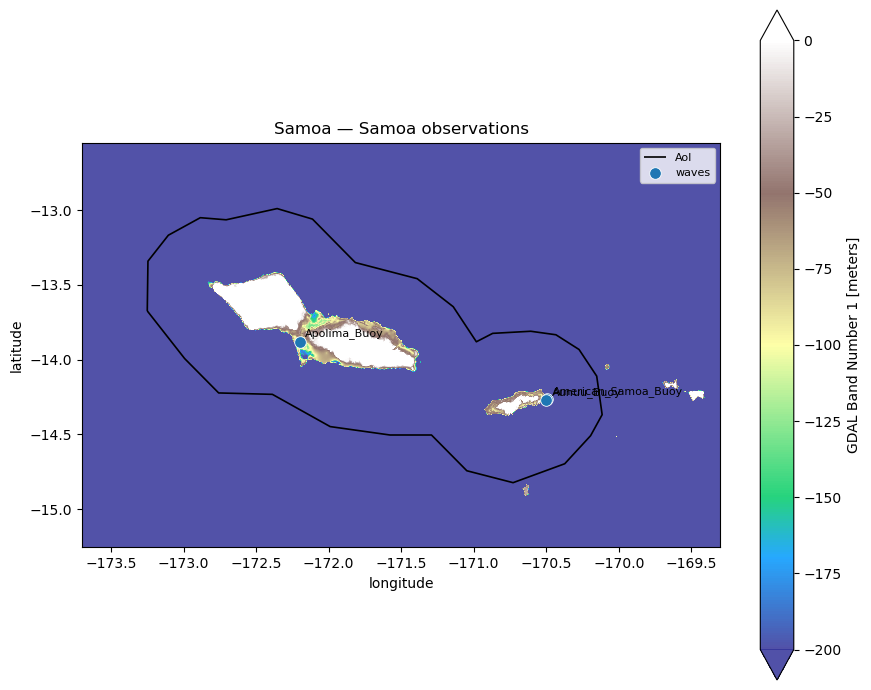

In [5]:
plot.plot_case_map(obs.dict_to_gdf(observations), title="Samoa observations")

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 3 feature(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json


## Update Samoa.json

After saving, add or update this key in `Samoa.json` so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/Samoa_observations.json"
```

Use the exact relative path you set in `output_observations_file`.